> **Portfolio-cleanup copy of the original notebook** (author: Kudzai Shava).
> Modelling code, parameters and saved outputs are unchanged. Only these edits were made: Dropbox download cells and links removed, data paths made relative (`../data/*.csv`), and this note added.
>
> **Read before relying on any result here:**
> - **The class named `iNNE` is not the published iNNE algorithm.** It scores each point by its mean distance to its 5 nearest neighbours and flags the top 5%. It is a k-nearest-neighbour distance score.
> - The confusion matrix compares two unsupervised detectors with different flag rates (iForest 1%, kNN score 5%). It shows agreement, not accuracy; there are no ground-truth labels.
> - Weather and generation tables are merged on `DATE_TIME` and `PLANT_ID` only (not inverter), so each weather row is repeated for every inverter at that timestamp.
> - There is no train/test split; models are fitted and scored on the same data, and the scaler/forest objects are refitted per plant.
> - No random seed is set, so flagged points will vary slightly between runs.
> - Saved outputs were produced in Google Colab; see `docs/technical-review.md` for what was re-run.


In [ ]:
# Original cell downloaded the data from private Dropbox copies with !wget (links removed).
# See ../data/README.md for the dataset sources and download instructions.
# Place the CSV files in ../data/ before running the cells below.

# EDA

In [ ]:
import pandas as pd

# Load the data from Plant 1 Weather Sensor Data
plant_1_weather_data = pd.read_csv('../data/Plant_1_Weather_Sensor_Data.csv')
plant_1_weather_data.info()
plant_1_weather_data


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3182 entries, 0 to 3181
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   DATE_TIME            3182 non-null   object 
 1   PLANT_ID             3182 non-null   int64  
 2   SOURCE_KEY           3182 non-null   object 
 3   AMBIENT_TEMPERATURE  3182 non-null   float64
 4   MODULE_TEMPERATURE   3182 non-null   float64
 5   IRRADIATION          3182 non-null   float64
dtypes: float64(3), int64(1), object(2)
memory usage: 149.3+ KB


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0
...,...,...,...,...,...,...
3177,2020-06-17 22:45:00,4135001,HmiyD2TTLFNqkNe,22.150570,21.480377,0.0
3178,2020-06-17 23:00:00,4135001,HmiyD2TTLFNqkNe,22.129816,21.389024,0.0
3179,2020-06-17 23:15:00,4135001,HmiyD2TTLFNqkNe,22.008275,20.709211,0.0
3180,2020-06-17 23:30:00,4135001,HmiyD2TTLFNqkNe,21.969495,20.734963,0.0


In [ ]:
import pandas as pd

# Load the data from Plant 1 generation Data
plant_1_generation_data = pd.read_csv('../data/Plant_1_Generation_Data.csv')
plant_1_generation_data.info()
plant_1_generation_data


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68778 entries, 0 to 68777
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATE_TIME    68778 non-null  object 
 1   PLANT_ID     68778 non-null  int64  
 2   SOURCE_KEY   68778 non-null  object 
 3   DC_POWER     68778 non-null  float64
 4   AC_POWER     68778 non-null  float64
 5   DAILY_YIELD  68778 non-null  float64
 6   TOTAL_YIELD  68778 non-null  float64
dtypes: float64(4), int64(1), object(2)
memory usage: 3.7+ MB


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.000,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.000,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.000,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.000,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.000,7158964.0
...,...,...,...,...,...,...,...
68773,17-06-2020 23:45,4135001,uHbuxQJl8lW7ozc,0.0,0.0,5967.000,7287002.0
68774,17-06-2020 23:45,4135001,wCURE6d3bPkepu2,0.0,0.0,5147.625,7028601.0
68775,17-06-2020 23:45,4135001,z9Y9gH1T5YWrNuG,0.0,0.0,5819.000,7251204.0
68776,17-06-2020 23:45,4135001,zBIq5rxdHJRwDNY,0.0,0.0,5817.000,6583369.0


In [ ]:
import pandas as pd

# Load the data from Plant 2 Weather Sensor Data
plant_2_weather_data = pd.read_csv('../data/Plant_2_Weather_Sensor_Data.csv')
plant_2_weather_data.info()
plant_2_weather_data


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3259 entries, 0 to 3258
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   DATE_TIME            3259 non-null   object 
 1   PLANT_ID             3259 non-null   int64  
 2   SOURCE_KEY           3259 non-null   object 
 3   AMBIENT_TEMPERATURE  3259 non-null   float64
 4   MODULE_TEMPERATURE   3259 non-null   float64
 5   IRRADIATION          3259 non-null   float64
dtypes: float64(3), int64(1), object(2)
memory usage: 152.9+ KB


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0
1,2020-05-15 00:15:00,4136001,iq8k7ZNt4Mwm3w0,26.880811,24.421869,0.0
2,2020-05-15 00:30:00,4136001,iq8k7ZNt4Mwm3w0,26.682055,24.427290,0.0
3,2020-05-15 00:45:00,4136001,iq8k7ZNt4Mwm3w0,26.500589,24.420678,0.0
4,2020-05-15 01:00:00,4136001,iq8k7ZNt4Mwm3w0,26.596148,25.088210,0.0
...,...,...,...,...,...,...
3254,2020-06-17 22:45:00,4136001,iq8k7ZNt4Mwm3w0,23.511703,22.856201,0.0
3255,2020-06-17 23:00:00,4136001,iq8k7ZNt4Mwm3w0,23.482282,22.744190,0.0
3256,2020-06-17 23:15:00,4136001,iq8k7ZNt4Mwm3w0,23.354743,22.492245,0.0
3257,2020-06-17 23:30:00,4136001,iq8k7ZNt4Mwm3w0,23.291048,22.373909,0.0


In [ ]:
import pandas as pd

# Load the data from Plant 2 generation Data
plant_2_generation_data = pd.read_csv('../data/Plant_2_Generation_Data.csv')
plant_2_generation_data.info()
plant_2_generation_data


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67698 entries, 0 to 67697
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   DATE_TIME    67698 non-null  object 
 1   PLANT_ID     67698 non-null  int64  
 2   SOURCE_KEY   67698 non-null  object 
 3   DC_POWER     67698 non-null  float64
 4   AC_POWER     67698 non-null  float64
 5   DAILY_YIELD  67698 non-null  float64
 6   TOTAL_YIELD  67698 non-null  float64
dtypes: float64(4), int64(1), object(2)
memory usage: 3.6+ MB


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15 00:00:00,4136001,4UPUqMRk7TRMgml,0.0,0.0,9425.000000,2.429011e+06
1,2020-05-15 00:00:00,4136001,81aHJ1q11NBPMrL,0.0,0.0,0.000000,1.215279e+09
2,2020-05-15 00:00:00,4136001,9kRcWv60rDACzjR,0.0,0.0,3075.333333,2.247720e+09
3,2020-05-15 00:00:00,4136001,Et9kgGMDl729KT4,0.0,0.0,269.933333,1.704250e+06
4,2020-05-15 00:00:00,4136001,IQ2d7wF4YD8zU1Q,0.0,0.0,3177.000000,1.994153e+07
...,...,...,...,...,...,...,...
67693,2020-06-17 23:45:00,4136001,q49J1IKaHRwDQnt,0.0,0.0,4157.000000,5.207580e+05
67694,2020-06-17 23:45:00,4136001,rrq4fwE8jgrTyWY,0.0,0.0,3931.000000,1.211314e+08
67695,2020-06-17 23:45:00,4136001,vOuJvMaM2sgwLmb,0.0,0.0,4322.000000,2.427691e+06
67696,2020-06-17 23:45:00,4136001,xMbIugepa2P7lBB,0.0,0.0,4218.000000,1.068964e+08


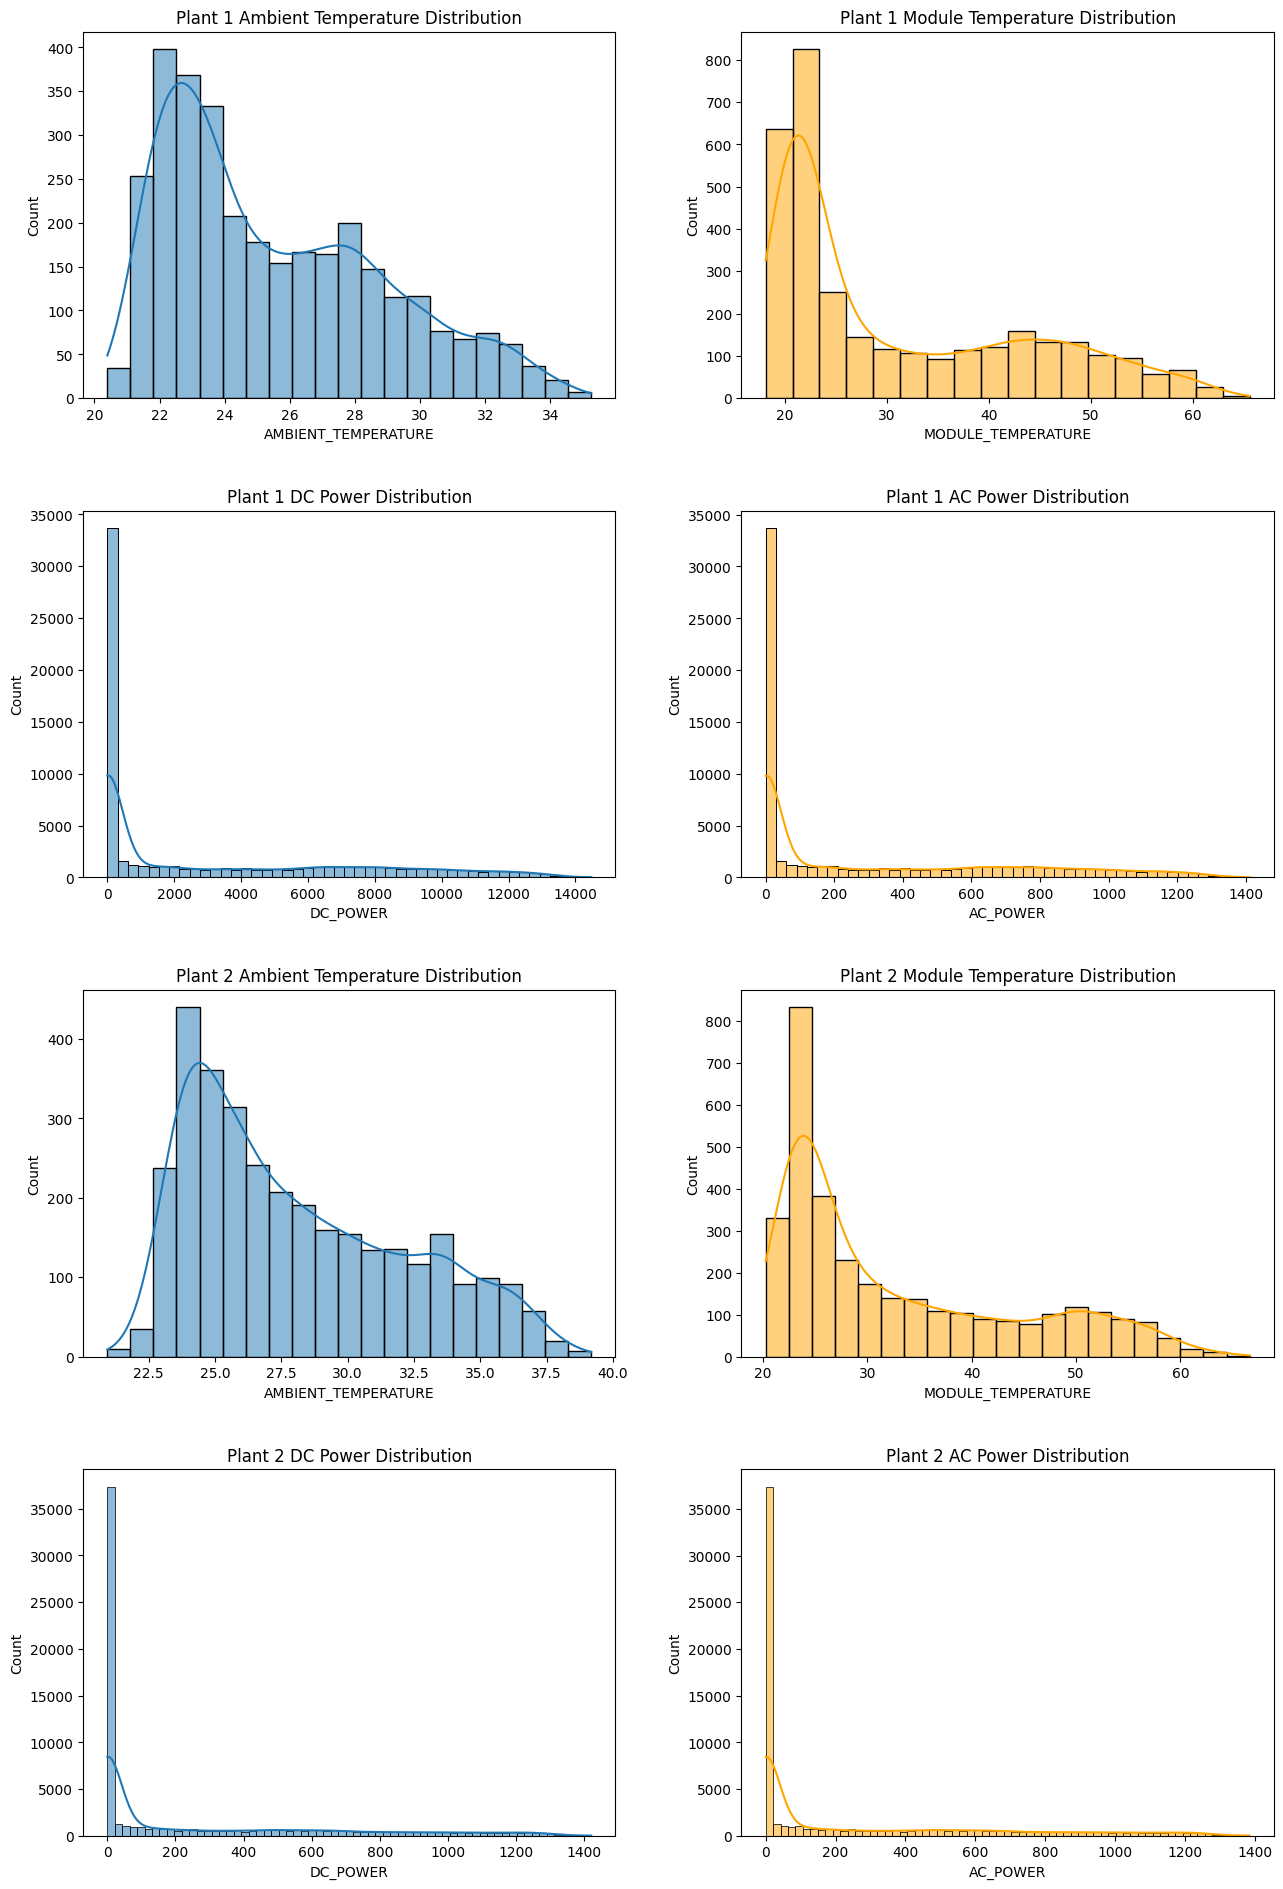

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Setting up the figure for multiple subplots
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(14, 20))
fig.tight_layout(pad=6.0)

# Weather Data - Ambient and Module Temperature Distribution for Plant 1
sns.histplot(plant_1_weather_data['AMBIENT_TEMPERATURE'], kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Plant 1 Ambient Temperature Distribution')
sns.histplot(plant_1_weather_data['MODULE_TEMPERATURE'], kde=True, color='orange', ax=axes[0, 1])
axes[0, 1].set_title('Plant 1 Module Temperature Distribution')

# Generation Data - DC and AC Power Distribution for Plant 1
sns.histplot(plant_1_generation_data['DC_POWER'], kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Plant 1 DC Power Distribution')
sns.histplot(plant_1_generation_data['AC_POWER'], kde=True, color='orange', ax=axes[1, 1])
axes[1, 1].set_title('Plant 1 AC Power Distribution')

# Weather Data - Ambient and Module Temperature Distribution for Plant 2
sns.histplot(plant_2_weather_data['AMBIENT_TEMPERATURE'], kde=True, ax=axes[2, 0])
axes[2, 0].set_title('Plant 2 Ambient Temperature Distribution')
sns.histplot(plant_2_weather_data['MODULE_TEMPERATURE'], kde=True, color='orange', ax=axes[2, 1])
axes[2, 1].set_title('Plant 2 Module Temperature Distribution')

# Generation Data - DC and AC Power Distribution for Plant 2
sns.histplot(plant_2_generation_data['DC_POWER'], kde=True, ax=axes[3, 0])
axes[3, 0].set_title('Plant 2 DC Power Distribution')
sns.histplot(plant_2_generation_data['AC_POWER'], kde=True, color='orange', ax=axes[3, 1])
axes[3, 1].set_title('Plant 2 AC Power Distribution')

plt.show()


# processing the data

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

# Load your datasets
plant_1_weather = pd.read_csv('../data/Plant_1_Weather_Sensor_Data.csv')
plant_1_generation = pd.read_csv('../data/Plant_1_Generation_Data.csv')
plant_2_weather = pd.read_csv('../data/Plant_2_Weather_Sensor_Data.csv')
plant_2_generation = pd.read_csv('../data/Plant_2_Generation_Data.csv')

# Ensure DATE_TIME formats are consistent
plant_1_weather['DATE_TIME'] = pd.to_datetime(plant_1_weather['DATE_TIME'])
plant_1_generation['DATE_TIME'] = pd.to_datetime(plant_1_generation['DATE_TIME'])
plant_2_weather['DATE_TIME'] = pd.to_datetime(plant_2_weather['DATE_TIME'])
plant_2_generation['DATE_TIME'] = pd.to_datetime(plant_2_generation['DATE_TIME'])

# Merge the datasets on DATE_TIME and PLANT_ID
plant_1_data = pd.merge(plant_1_weather, plant_1_generation, on=['DATE_TIME', 'PLANT_ID'])
plant_2_data = pd.merge(plant_2_weather, plant_2_generation, on=['DATE_TIME', 'PLANT_ID'])

print("Rows in Plant 1 merged data:", plant_1_data.shape[0])
print("Rows in Plant 2 merged data:", plant_2_data.shape[0])

# Check if any dataset is empty and handle it
if plant_1_data.empty or plant_2_data.empty:
    raise ValueError("One of the datasets is empty after merge. Check the keys and data compatibility.")


Rows in Plant 1 merged data: 68774
Rows in Plant 2 merged data: 67698


<ipython-input-73-16bd215560a0>:13: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  plant_1_generation['DATE_TIME'] = pd.to_datetime(plant_1_generation['DATE_TIME'])


In [ ]:
# Handle missing values for numeric columns only
numeric_columns_1 = plant_1_data.select_dtypes(include=['float64', 'int64']).columns
numeric_columns_2 = plant_2_data.select_dtypes(include=['float64', 'int64']).columns

plant_1_data[numeric_columns_1] = plant_1_data[numeric_columns_1].fillna(plant_1_data[numeric_columns_1].median())
plant_2_data[numeric_columns_2] = plant_2_data[numeric_columns_2].fillna(plant_2_data[numeric_columns_2].median())

# Feature Engineering - Create temperature difference feature
plant_1_data['TEMP_DIFF'] = plant_1_data['MODULE_TEMPERATURE'] - plant_1_data['AMBIENT_TEMPERATURE']
plant_2_data['TEMP_DIFF'] = plant_2_data['MODULE_TEMPERATURE'] - plant_2_data['AMBIENT_TEMPERATURE']

# Select features for the model
features = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD', 'TEMP_DIFF']
X1 = plant_1_data[features]
X2 = plant_2_data[features]

# Scale the features
scaler = StandardScaler()
X1_scaled = scaler.fit_transform(X1)
X2_scaled = scaler.fit_transform(X2)


# iForest

In [ ]:
import time

# Now you can fit the Isolation Forest model
iforest = IsolationForest(n_estimators=100, contamination=0.01)  # contamination is an estimate of the anomaly percentage
start_time = time.time()

iforest.fit(X1_scaled)
train_time = time.time() - start_time

# Predict anomalies
start_time = time.time()
anomalies_1 = iforest.predict(X1_scaled)
prediction_time = time.time() - start_time

plant_1_data['anomaly_iForest'] = anomalies_1

# Check the anomaly data
plant_1_data[plant_1_data['anomaly_iForest'] == -1].head()  # -1 indicates an anomaly


,DATE_TIME,PLANT_ID,SOURCE_KEY_x,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,SOURCE_KEY_y,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,TEMP_DIFF,anomaly_iForest
1235,2020-05-15 14:15:00,4135001,HmiyD2TTLFNqkNe,34.130770,55.030613,0.893661,1IF53ai7Xc0U56Y,12194.71429,1189.642857,4628.714286,6188273.714,20.899843,-1
1244,2020-05-15 14:15:00,4135001,HmiyD2TTLFNqkNe,34.130770,55.030613,0.893661,adLQvlD726eNBSB,12319.14286,1201.442857,4633.142857,6275988.143,20.899843,-1
1269,2020-05-15 14:30:00,4135001,HmiyD2TTLFNqkNe,34.081384,54.519137,0.466789,ih0vzX44oOqAx2f,4514.20000,443.080000,4773.400000,6189946.167,20.437752,-1
4878,2020-05-17 11:15:00,4135001,HmiyD2TTLFNqkNe,31.531130,60.208570,0.997904,1BY6WEcLGh8j5v7,10160.14286,991.828571,2945.142857,6274550.143,28.677440,-1
4879,2020-05-17 11:15:00,4135001,HmiyD2TTLFNqkNe,31.531130,60.208570,0.997904,1IF53ai7Xc0U56Y,12995.50000,1267.075000,3265.500000,6199859.500,28.677440,-1


In [ ]:
train_time

1.7969284057617188

In [ ]:
prediction_time

1.7397489547729492

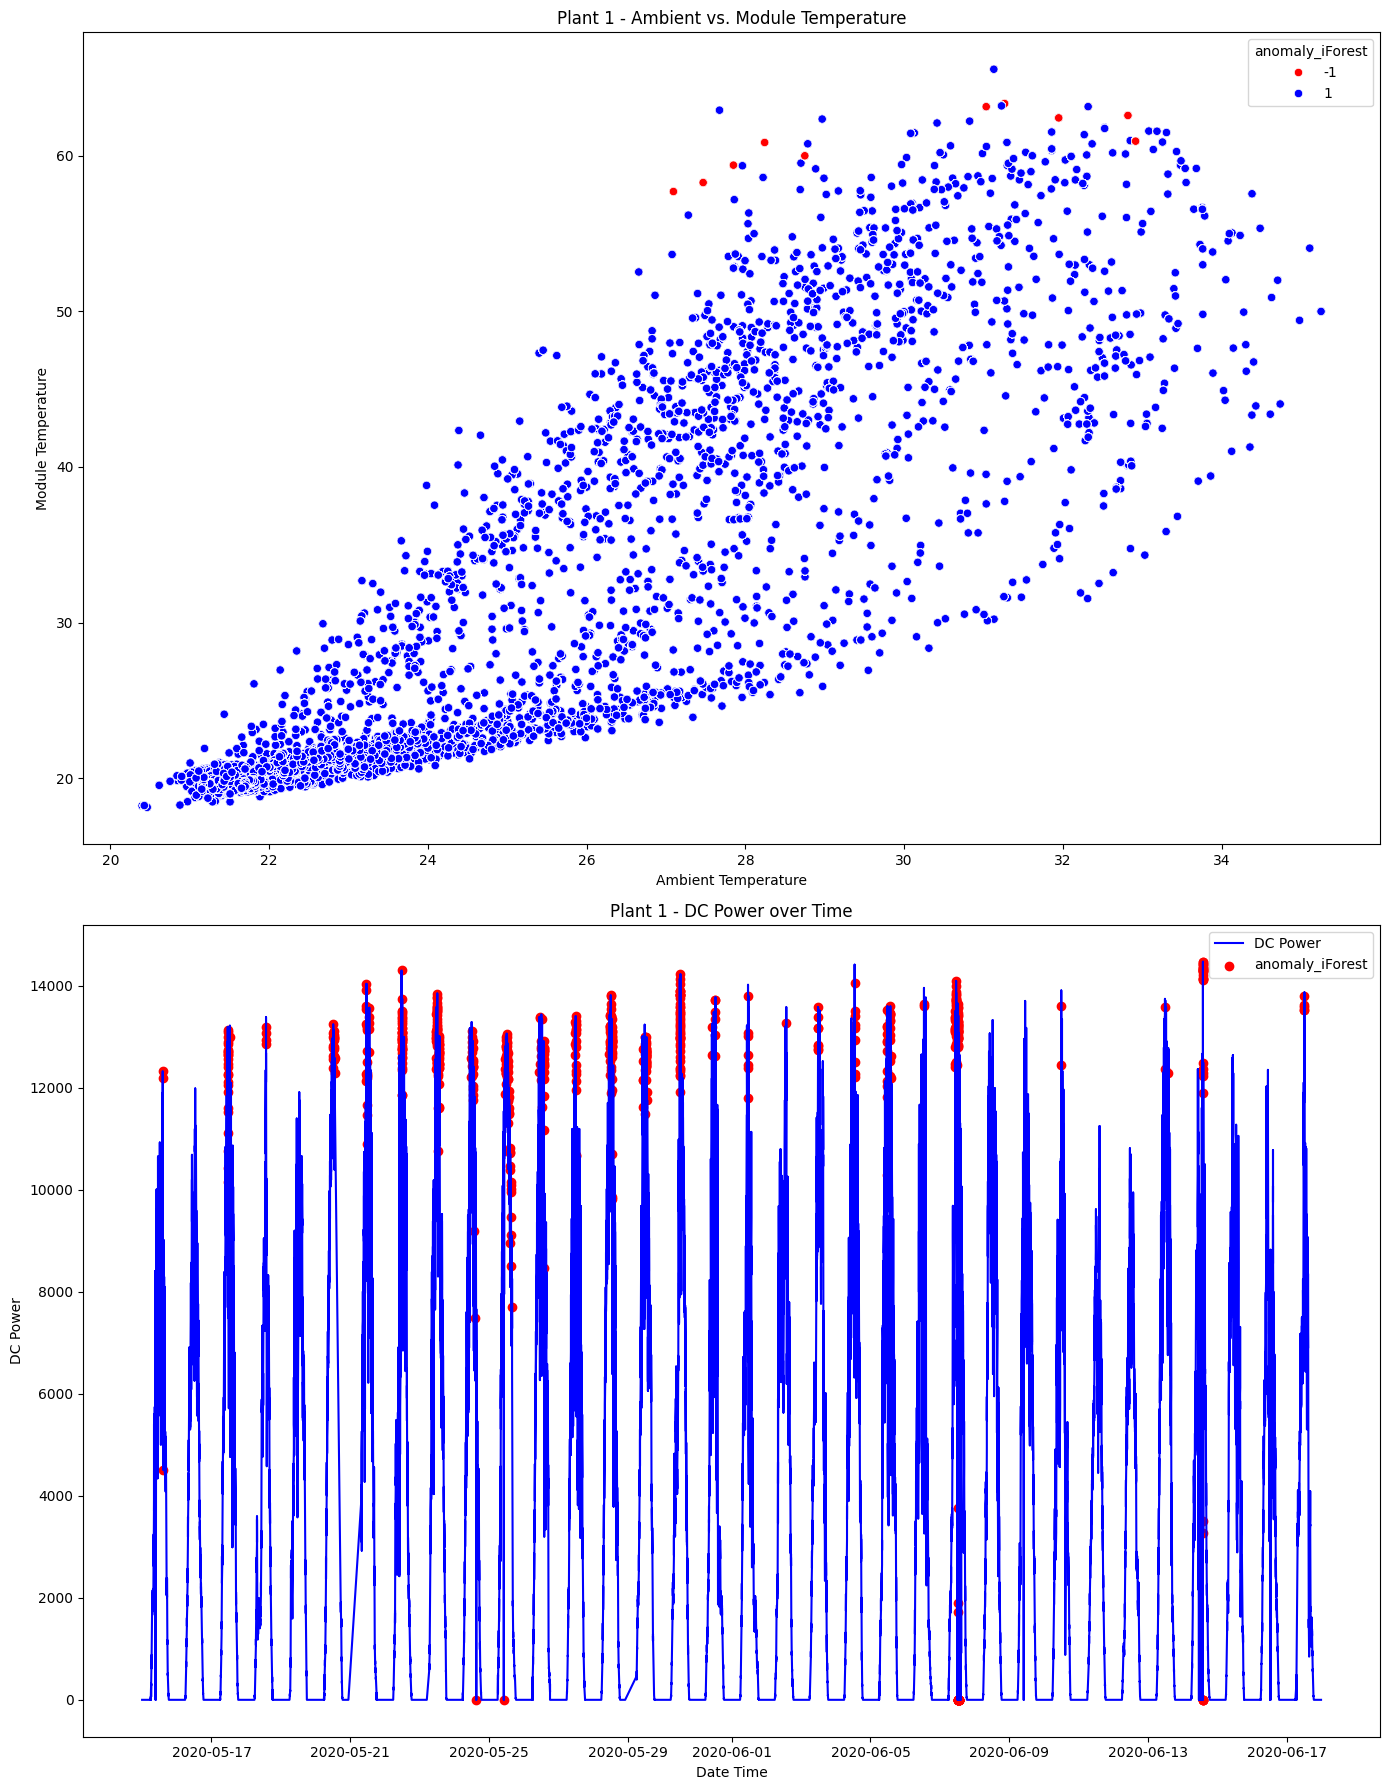

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_anomalies(data, title):
    fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(14, 18))

    # Scatter plot of Ambient vs. Module Temperature
    sns.scatterplot(x='AMBIENT_TEMPERATURE', y='MODULE_TEMPERATURE', hue='anomaly_iForest', data=data, ax=ax[0], palette={1: 'blue', -1: 'red'})
    ax[0].set_title(f'{title} - Ambient vs. Module Temperature')
    ax[0].set_xlabel('Ambient Temperature')
    ax[0].set_ylabel('Module Temperature')

    # Time series plot of DC Power
    ax[1].plot(data['DATE_TIME'], data['DC_POWER'], label='DC Power', color='blue')
    ax[1].scatter(data['DATE_TIME'][data['anomaly_iForest'] == -1], data['DC_POWER'][data['anomaly_iForest'] == -1], color='red', label='anomaly_iForest')
    ax[1].set_title(f'{title} - DC Power over Time')
    ax[1].set_xlabel('Date Time')
    ax[1].set_ylabel('DC Power')
    ax[1].legend()

    plt.tight_layout()
    plt.show()

# Plot for Plant 1
plot_anomalies(plant_1_data, 'Plant 1')


In [ ]:
# Do the same for Plant 2 if needed
start_time = time.time()

iforest.fit(X2_scaled)
train_time = time.time() - start_time

# Predict anomalies
start_time = time.time()
anomalies_2 = iforest.predict(X2_scaled)
prediction_time = time.time() - start_time

plant_2_data['anomaly_iForest'] = anomalies_2

# Check the anomaly data
plant_2_data[plant_2_data['anomaly_iForest'] == -1].head()  # -1 indicates an anomaly


,DATE_TIME,PLANT_ID,SOURCE_KEY_x,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,SOURCE_KEY_y,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,TEMP_DIFF,anomaly_iForest
970,2020-05-15 11:00:00,4136001,iq8k7ZNt4Mwm3w0,33.462057,51.610991,0.957900,9kRcWv60rDACzjR,1254.760000,1223.386667,3390.933333,2.247723e+09,18.148935,-1
1014,2020-05-15 11:30:00,4136001,iq8k7ZNt4Mwm3w0,34.651455,56.083953,0.987932,9kRcWv60rDACzjR,1273.593333,1241.766667,3991.400000,2.247724e+09,21.432498,-1
1080,2020-05-15 12:15:00,4136001,iq8k7ZNt4Mwm3w0,36.377571,57.588582,0.977188,9kRcWv60rDACzjR,1259.793333,1228.293333,4919.000000,2.247724e+09,21.211011,-1
1083,2020-05-15 12:15:00,4136001,iq8k7ZNt4Mwm3w0,36.377571,57.588582,0.977188,LYwnQax7tkwH5Cb,1270.378571,1238.614286,4657.642857,1.794963e+09,21.211011,-1
1093,2020-05-15 12:15:00,4136001,iq8k7ZNt4Mwm3w0,36.377571,57.588582,0.977188,oZ35aAeoifZaQzV,1292.553333,1260.226667,5072.000000,1.659970e+09,21.211011,-1


In [ ]:
train_time

1.6620805263519287

In [ ]:
prediction_time

1.393833875656128

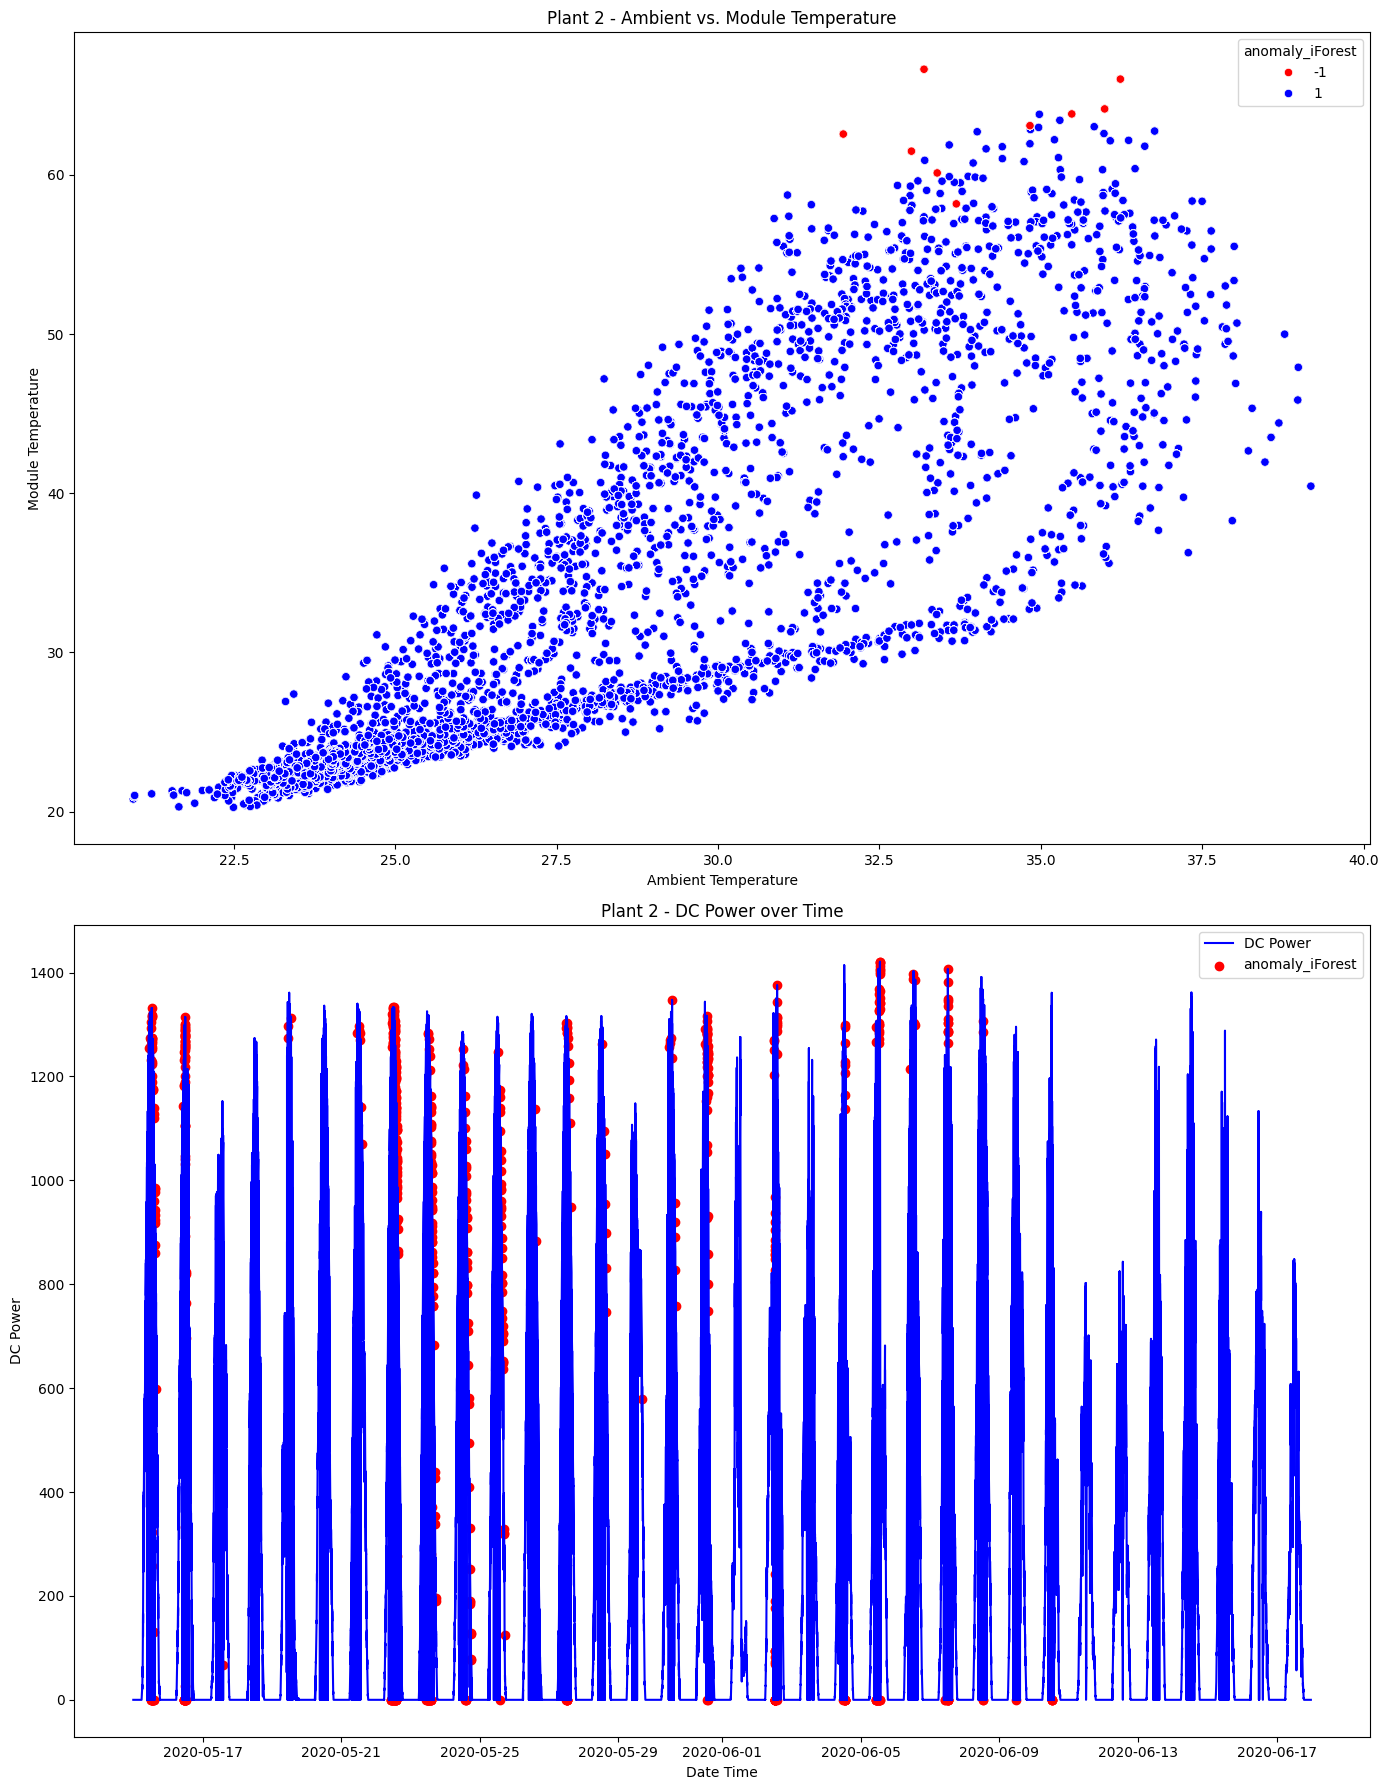

In [ ]:
# Plot for Plant 2
plot_anomalies(plant_2_data, 'Plant 2')


# iNNE

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, OutlierMixin
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Implementing the iNNE class
class iNNE(BaseEstimator, OutlierMixin):
    def __init__(self, n_neighbors=5, contamination=0.1):
        self.n_neighbors = n_neighbors
        self.contamination = contamination

    def fit(self, X, y=None):
        self.neighbors_ = NearestNeighbors(n_neighbors=self.n_neighbors)
        self.neighbors_.fit(X)
        distances, indices = self.neighbors_.kneighbors(X)

        # Calculate the anomaly score based on distances
        self.scores_ = np.mean(distances, axis=1)
        self.threshold_ = np.percentile(self.scores_, 100 * (1 - self.contamination))
        return self

    def predict(self, X):
        distances, indices = self.neighbors_.kneighbors(X)
        scores = np.mean(distances, axis=1)
        return np.where(scores > self.threshold_, -1, 1)

# Assuming 'plant_1_data' and 'plant_2_data' are already loaded and preprocessed
# Select features
features = ['AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD', 'TEMP_DIFF']
X1 = plant_1_data[features]
X2 = plant_2_data[features]

# Scale the features
scaler = StandardScaler()
X1_scaled = scaler.fit_transform(X1)
X2_scaled = scaler.fit_transform(X2)


In [ ]:
# Create the iNNE model
inne_model = iNNE(n_neighbors=5, contamination=0.05)

# Fit the model
inne_model.fit(X1_scaled)

# Predict anomalies
anomalies_1 = inne_model.predict(X1_scaled)
plant_1_data['anomaly_iNNE'] = anomalies_1
plant_1_data.head()


,DATE_TIME,PLANT_ID,SOURCE_KEY_x,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,SOURCE_KEY_y,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,TEMP_DIFF,anomaly_iForest,anomaly_iNNE
0,2020-05-15,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0,-2.326809,1,1
1,2020-05-15,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0,-2.326809,1,1
2,2020-05-15,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0,-2.326809,1,1
3,2020-05-15,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0,-2.326809,1,1
4,2020-05-15,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0,-2.326809,1,1


In [ ]:
# Repeat for Plant 2 if needed
inne_model.fit(X2_scaled)
anomalies_2 = inne_model.predict(X2_scaled)
plant_2_data['anomaly_iNNE'] = anomalies_2
plant_2_data.head()


,DATE_TIME,PLANT_ID,SOURCE_KEY_x,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,SOURCE_KEY_y,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD,TEMP_DIFF,anomaly_iForest,anomaly_iNNE
0,2020-05-15,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,4UPUqMRk7TRMgml,0.0,0.0,9425.000000,2.429011e+06,-1.943975,1,1
1,2020-05-15,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,81aHJ1q11NBPMrL,0.0,0.0,0.000000,1.215279e+09,-1.943975,1,1
2,2020-05-15,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,9kRcWv60rDACzjR,0.0,0.0,3075.333333,2.247720e+09,-1.943975,1,1
3,2020-05-15,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,Et9kgGMDl729KT4,0.0,0.0,269.933333,1.704250e+06,-1.943975,1,1
4,2020-05-15,4136001,iq8k7ZNt4Mwm3w0,27.004764,25.060789,0.0,IQ2d7wF4YD8zU1Q,0.0,0.0,3177.000000,1.994153e+07,-1.943975,1,1


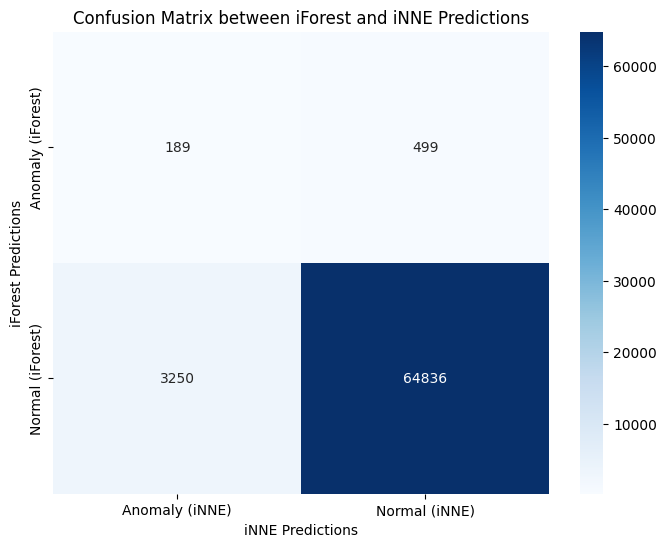

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

# Assuming plant_1_data has the columns 'anomaly_iForest' and 'anomaly_iNNE'
conf_matrix = confusion_matrix(plant_1_data['anomaly_iForest'], plant_1_data['anomaly_iNNE'], labels=[-1, 1])

# Plotting the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=['Anomaly (iNNE)', 'Normal (iNNE)'], yticklabels=['Anomaly (iForest)', 'Normal (iForest)'])
plt.title('Confusion Matrix between iForest and iNNE Predictions')
plt.ylabel('iForest Predictions')
plt.xlabel('iNNE Predictions')
plt.show()
